In [1]:
from importlib.util import find_spec
from pathlib import Path

import numpy as np
import pandas as pd
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

CHART_CONFIG = {
    "displaylogo": False,
    "responsive": True,
}

print("Plotly version:", plotly.__version__)

Plotly version: 6.8.0


In [2]:
customers_shopping = pd.read_csv(
    DATA_DIR/"customer_shopping_behavior.csv",
)
customers_shopping.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Transaction ID          10000 non-null  str  
 1   Customer ID             10000 non-null  str  
 2   Purchase Date           10000 non-null  str  
 3   Age                     10000 non-null  int64
 4   Gender                  10000 non-null  str  
 5   Location                10000 non-null  str  
 6   Online/Offline          10000 non-null  str  
 7   Online Store            7751 non-null   str  
 8   Category                10000 non-null  str  
 9   Item Purchased          10000 non-null  str  
 10  Brand                   10000 non-null  str  
 11  Color                   10000 non-null  str  
 12  Size                    8965 non-null   str  
 13  Quantity                10000 non-null  int64
 14  Purchase Amount (₹)     10000 non-null  int64
 15  Discount (%)            10000 n

In [3]:
customers_shopping.describe()

,Age,Quantity,Purchase Amount (₹),Discount (%),Shipping Charge (₹),Delivery Time (Days),Review Rating,Previous Purchases
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,38.278100,1.425100,1889.882000,32.916300,41.49210,3.703600,3.874900,3.211400
std,12.133041,0.761346,2102.301836,21.440617,64.30923,2.726223,0.912871,3.951313
min,18.000000,1.000000,67.000000,0.000000,0.00000,0.000000,1.000000,0.000000
25%,28.000000,1.000000,600.000000,12.000000,0.00000,1.000000,3.000000,0.000000
50%,38.000000,1.000000,1207.000000,33.000000,0.00000,4.000000,4.000000,2.000000
75%,49.000000,2.000000,2376.000000,52.000000,79.00000,6.000000,5.000000,4.000000
max,59.000000,4.000000,22306.000000,70.000000,199.00000,8.000000,5.000000,28.000000


In [4]:
print(customers_shopping.isna().sum())

Transaction ID               0
Customer ID                  0
Purchase Date                0
Age                          0
Gender                       0
Location                     0
Online/Offline               0
Online Store              2249
Category                     0
Item Purchased               0
Brand                        0
Color                        0
Size                      1035
Quantity                     0
Purchase Amount (₹)          0
Discount (%)                 0
Festival/Sale             6788
Shipping Charge (₹)          0
Delivery Speed            2249
Delivery Time (Days)         0
Subscription Status          0
Payment Method               0
Review Rating                0
Return Status                0
Previous Purchases           0
Frequency of Purchases       0
dtype: int64


In [5]:
customers_shopping.dtypes


Transaction ID              str
Customer ID                 str
Purchase Date               str
Age                       int64
Gender                      str
Location                    str
Online/Offline              str
Online Store                str
Category                    str
Item Purchased              str
Brand                       str
Color                       str
Size                        str
Quantity                  int64
Purchase Amount (₹)       int64
Discount (%)              int64
Festival/Sale               str
Shipping Charge (₹)       int64
Delivery Speed              str
Delivery Time (Days)      int64
Subscription Status         str
Payment Method              str
Review Rating             int64
Return Status               str
Previous Purchases        int64
Frequency of Purchases      str
dtype: object

In [6]:
customers_shopping.head()

,Transaction ID,Customer ID,Purchase Date,Age,Gender,Location,Online/Offline,Online Store,Category,Item Purchased,...,Festival/Sale,Shipping Charge (₹),Delivery Speed,Delivery Time (Days),Subscription Status,Payment Method,Review Rating,Return Status,Previous Purchases,Frequency of Purchases
0,TXN507808,CUST102534,2023-01-01,51,Male,Chennai,Online,Flipkart,Clothing,Kurta,...,NaN,0,Same Day,1,Yes,Cash on Delivery,4,Not Returned,0,Fortnightly
1,TXN503830,CUST101256,2023-01-01,27,Female,Mumbai,Offline,NaN,Clothing,Shirt,...,NaN,0,NaN,0,No,UPI,5,Not Returned,0,Fortnightly
2,TXN501496,CUST100490,2023-01-01,57,Male,Hyderabad,Online,Flipkart,Clothing,Jacket,...,NaN,0,Standard,7,Yes,UPI,3,Not Returned,0,Rarely
3,TXN501538,CUST100500,2023-01-01,22,Female,Pune,Online,Myntra,Clothing,Kurta,...,NaN,0,Standard,6,Yes,Net Banking,4,Not Returned,0,Fortnightly
4,TXN504265,CUST101399,2023-01-01,30,Male,Visakhapatnam,Online,Myntra,Accessories,Cap,...,NaN,99,Express,2,No,Debit Card,4,Not Returned,0,Weekly


In [7]:
customers_shopping.shape

(10000, 26)

In [8]:
customers_shopping["Transaction ID"].nunique()

10000

In [9]:
date_format = "%Y-%m-%d"
customers_shopping["Purchase Date"]=pd.to_datetime(
    customers_shopping["Purchase Date"],
    format=date_format,
    errors="coerce")
customers_shopping.dtypes

Transaction ID                       str
Customer ID                          str
Purchase Date             datetime64[us]
Age                                int64
Gender                               str
Location                             str
Online/Offline                       str
Online Store                         str
Category                             str
Item Purchased                       str
Brand                                str
Color                                str
Size                                 str
Quantity                           int64
Purchase Amount (₹)                int64
Discount (%)                       int64
Festival/Sale                        str
Shipping Charge (₹)                int64
Delivery Speed                       str
Delivery Time (Days)               int64
Subscription Status                  str
Payment Method                       str
Review Rating                      int64
Return Status                        str
Previous Purchas

In [10]:
print(customers_shopping["Purchase Date"].isna().sum())
print(customers_shopping["Purchase Date"].nunique())

0
731


In [11]:
print(customers_shopping["Purchase Date"].min())
print(customers_shopping["Purchase Date"].max())

2023-01-01 00:00:00
2024-12-31 00:00:00


In [12]:
customers_shopping["Year"] = customers_shopping["Purchase Date"].dt.year
customers_shopping["Month"] = customers_shopping["Purchase Date"].dt.month
customers_shopping["Month_Name"] = customers_shopping["Purchase Date"].dt.month_name()
customers_shopping["Day"] = customers_shopping["Purchase Date"].dt.day
customers_shopping["Day_Name"] = customers_shopping["Purchase Date"].dt.day_name()

In [13]:
customers_shopping.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Transaction ID          10000 non-null  str           
 1   Customer ID             10000 non-null  str           
 2   Purchase Date           10000 non-null  datetime64[us]
 3   Age                     10000 non-null  int64         
 4   Gender                  10000 non-null  str           
 5   Location                10000 non-null  str           
 6   Online/Offline          10000 non-null  str           
 7   Online Store            7751 non-null   str           
 8   Category                10000 non-null  str           
 9   Item Purchased          10000 non-null  str           
 10  Brand                   10000 non-null  str           
 11  Color                   10000 non-null  str           
 12  Size                    8965 non-null   str           
 13

In [14]:
customers_shopping["Age"].describe()

count    10000.000000
mean        38.278100
std         12.133041
min         18.000000
25%         28.000000
50%         38.000000
75%         49.000000
max         59.000000
Name: Age, dtype: float64

In [15]:
customers_shopping["Gender"].value_counts()

Gender
Male      5449
Female    4551
Name: count, dtype: int64

In [16]:
print(customers_shopping["Location"].value_counts())

Location
Pune             974
Mumbai           958
Chennai          938
Bangalore        935
Kolkata          913
Hyderabad        869
Delhi            773
Kochi            335
Chandigarh       335
Bhubaneswar      334
Nagpur           316
Ahmedabad        315
Jaipur           311
Noida            274
Surat            269
Gurgaon          267
Visakhapatnam    258
Lucknow          237
Indore           220
Patna            169
Name: count, dtype: int64


In [17]:
customers_shopping["Location"] = customers_shopping["Location"].str.strip()
print(customers_shopping["Location"].unique())

<ArrowStringArray>
[      'Chennai',        'Mumbai',     'Hyderabad',          'Pune',
 'Visakhapatnam',         'Kochi',     'Ahmedabad',    'Chandigarh',
         'Delhi',     'Bangalore',        'Indore',        'Jaipur',
       'Kolkata',         'Patna',       'Lucknow',        'Nagpur',
         'Noida',         'Surat',   'Bhubaneswar',       'Gurgaon']
Length: 20, dtype: str


In [18]:
customers_shopping["Online/Offline"].value_counts()

Online/Offline
Online     7751
Offline    2249
Name: count, dtype: int64

In [19]:
customers_shopping["Online Store"] = customers_shopping["Online Store"].fillna("Not Applicable")
customers_shopping.isna().sum()

Transaction ID               0
Customer ID                  0
Purchase Date                0
Age                          0
Gender                       0
Location                     0
Online/Offline               0
Online Store                 0
Category                     0
Item Purchased               0
Brand                        0
Color                        0
Size                      1035
Quantity                     0
Purchase Amount (₹)          0
Discount (%)                 0
Festival/Sale             6788
Shipping Charge (₹)          0
Delivery Speed            2249
Delivery Time (Days)         0
Subscription Status          0
Payment Method               0
Review Rating                0
Return Status                0
Previous Purchases           0
Frequency of Purchases       0
Year                         0
Month                        0
Month_Name                   0
Day                          0
Day_Name                     0
dtype: int64

In [20]:
customers_shopping["Online Store"].value_counts()

Online Store
Not Applicable    2249
Myntra            2078
Amazon            1743
Flipkart          1594
Ajio              1163
Meesho             714
Shein              459
Name: count, dtype: int64

In [21]:
customers_shopping["Category"].value_counts()

Category
Clothing       5003
Footwear       2838
Accessories    2159
Name: count, dtype: int64

In [22]:
customers_shopping["Item Purchased"].value_counts()

Item Purchased
Dress            617
Boots            571
Jacket           543
Saree            543
T-shirt          527
Hoodie           522
Sandals          521
Shorts           499
Kurta            476
Slippers         454
Jeans            443
Running Shoes    439
Shirt            435
Sneakers         435
Formal Shoes     418
Trousers         398
Bag              359
Sunglasses       298
Socks            256
Backpack         256
Cap              253
Belt             251
Watch            245
Wallet           241
Name: count, dtype: int64

In [23]:
customers_shopping["Brand"].value_counts()

Brand
HRX            999
Puma           994
Max            978
H&M            905
Zara           869
Roadster       850
Nike           837
US Polo        837
Bewakoof       687
Levis          686
Allen Solly    604
Bata           440
Campus         314
Name: count, dtype: int64

In [24]:
customers_shopping["Color"].value_counts()

Color
Beige     1072
Blue       967
Navy       956
Black      936
Brown      932
Pink       908
White      900
Grey       875
Yellow     848
Green      832
Red        774
Name: count, dtype: int64

In [25]:
customers_shopping["Size"].value_counts()

Size
M            1490
L            1250
Free Size    1124
S             998
XL            750
9             505
11            495
8             478
6             467
10            454
7             439
XS            271
XXL           244
Name: count, dtype: int64

In [26]:
customers_shopping["Size"] = customers_shopping["Size"].fillna("Not Specified")
customers_shopping.isna().sum()

Transaction ID               0
Customer ID                  0
Purchase Date                0
Age                          0
Gender                       0
Location                     0
Online/Offline               0
Online Store                 0
Category                     0
Item Purchased               0
Brand                        0
Color                        0
Size                         0
Quantity                     0
Purchase Amount (₹)          0
Discount (%)                 0
Festival/Sale             6788
Shipping Charge (₹)          0
Delivery Speed            2249
Delivery Time (Days)         0
Subscription Status          0
Payment Method               0
Review Rating                0
Return Status                0
Previous Purchases           0
Frequency of Purchases       0
Year                         0
Month                        0
Month_Name                   0
Day                          0
Day_Name                     0
dtype: int64

In [27]:
customers_shopping["Quantity"].value_counts().sort_index()

Quantity
1    7106
2    1856
3     719
4     319
Name: count, dtype: int64

In [28]:
customers_shopping["Purchase Amount (₹)"].describe()

count    10000.000000
mean      1889.882000
std       2102.301836
min         67.000000
25%        600.000000
50%       1207.000000
75%       2376.000000
max      22306.000000
Name: Purchase Amount (₹), dtype: float64

In [29]:
customers_shopping["Discount (%)"].describe()

count    10000.000000
mean        32.916300
std         21.440617
min          0.000000
25%         12.000000
50%         33.000000
75%         52.000000
max         70.000000
Name: Discount (%), dtype: float64

In [30]:
customers_shopping["Festival/Sale"].value_counts(dropna=False)

Festival/Sale
NaN                         6788
End of Season Sale           517
Big Billion Days             467
Holi Sale                    455
Independence Day Sale        453
Diwali Sale                  451
Republic Day Sale            437
Amazon Great Summer Sale     432
Name: count, dtype: int64

In [31]:
customers_shopping["Festival/Sale"] = customers_shopping["Festival/Sale"].fillna("No Sale")
customers_shopping.isna().sum()

Transaction ID               0
Customer ID                  0
Purchase Date                0
Age                          0
Gender                       0
Location                     0
Online/Offline               0
Online Store                 0
Category                     0
Item Purchased               0
Brand                        0
Color                        0
Size                         0
Quantity                     0
Purchase Amount (₹)          0
Discount (%)                 0
Festival/Sale                0
Shipping Charge (₹)          0
Delivery Speed            2249
Delivery Time (Days)         0
Subscription Status          0
Payment Method               0
Review Rating                0
Return Status                0
Previous Purchases           0
Frequency of Purchases       0
Year                         0
Month                        0
Month_Name                   0
Day                          0
Day_Name                     0
dtype: int64

In [32]:
customers_shopping["Shipping Charge (₹)"].value_counts()

Shipping Charge (₹)
0      6421
199     775
49      720
99      715
79      705
149     664
Name: count, dtype: int64

In [33]:
customers_shopping["Free_Shipping"] = np.where(
    customers_shopping["Shipping Charge (₹)"] == 0,
    "Yes",
    "No"
)
customers_shopping.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Transaction ID          10000 non-null  str           
 1   Customer ID             10000 non-null  str           
 2   Purchase Date           10000 non-null  datetime64[us]
 3   Age                     10000 non-null  int64         
 4   Gender                  10000 non-null  str           
 5   Location                10000 non-null  str           
 6   Online/Offline          10000 non-null  str           
 7   Online Store            10000 non-null  str           
 8   Category                10000 non-null  str           
 9   Item Purchased          10000 non-null  str           
 10  Brand                   10000 non-null  str           
 11  Color                   10000 non-null  str           
 12  Size                    10000 non-null  str           
 13

In [34]:
customers_shopping["Delivery Speed"] = customers_shopping["Delivery Speed"].fillna("Not Applicable")
customers_shopping.isna().sum()

Transaction ID            0
Customer ID               0
Purchase Date             0
Age                       0
Gender                    0
Location                  0
Online/Offline            0
Online Store              0
Category                  0
Item Purchased            0
Brand                     0
Color                     0
Size                      0
Quantity                  0
Purchase Amount (₹)       0
Discount (%)              0
Festival/Sale             0
Shipping Charge (₹)       0
Delivery Speed            0
Delivery Time (Days)      0
Subscription Status       0
Payment Method            0
Review Rating             0
Return Status             0
Previous Purchases        0
Frequency of Purchases    0
Year                      0
Month                     0
Month_Name                0
Day                       0
Day_Name                  0
Free_Shipping             0
dtype: int64

In [35]:
customers_shopping["Delivery Applicable"] = np.where(
    customers_shopping["Online/Offline"] == "Online",
    "Yes",
    "No"
)
customers_shopping.isna().sum()

Transaction ID            0
Customer ID               0
Purchase Date             0
Age                       0
Gender                    0
Location                  0
Online/Offline            0
Online Store              0
Category                  0
Item Purchased            0
Brand                     0
Color                     0
Size                      0
Quantity                  0
Purchase Amount (₹)       0
Discount (%)              0
Festival/Sale             0
Shipping Charge (₹)       0
Delivery Speed            0
Delivery Time (Days)      0
Subscription Status       0
Payment Method            0
Review Rating             0
Return Status             0
Previous Purchases        0
Frequency of Purchases    0
Year                      0
Month                     0
Month_Name                0
Day                       0
Day_Name                  0
Free_Shipping             0
Delivery Applicable       0
dtype: int64

In [36]:
customers_shopping["Subscription Status"].value_counts()

Subscription Status
No     6881
Yes    3119
Name: count, dtype: int64

In [37]:
customers_shopping["Payment Method"].value_counts()

Payment Method
UPI                 4411
Credit Card         1582
Debit Card          1533
Cash on Delivery     987
Net Banking          586
Wallet               471
EMI                  430
Name: count, dtype: int64

In [38]:
customers_shopping["Review Rating"].value_counts().sort_values(ascending = True)

Review Rating
1      56
2     659
3    2557
5    2792
4    3936
Name: count, dtype: int64

In [39]:
customers_shopping[
    (customers_shopping["Review Rating"] < 1) |
    (customers_shopping["Review Rating"] > 5)
]

,Transaction ID,Customer ID,Purchase Date,Age,Gender,Location,Online/Offline,Online Store,Category,Item Purchased,...,Return Status,Previous Purchases,Frequency of Purchases,Year,Month,Month_Name,Day,Day_Name,Free_Shipping,Delivery Applicable


In [40]:
customers_shopping["Return Status"].value_counts()

Return Status
Not Returned    8198
Returned        1802
Name: count, dtype: int64

In [41]:
customers_shopping["Previous Purchases"].describe()

count    10000.000000
mean         3.211400
std          3.951313
min          0.000000
25%          0.000000
50%          2.000000
75%          4.000000
max         28.000000
Name: Previous Purchases, dtype: float64

In [42]:
customers_shopping["Customer Type"] = np.where(
    customers_shopping["Previous Purchases"] == 0,
    "New Customer",
    "Returning Customer"
)
customers_shopping.isna().sum()

Transaction ID            0
Customer ID               0
Purchase Date             0
Age                       0
Gender                    0
Location                  0
Online/Offline            0
Online Store              0
Category                  0
Item Purchased            0
Brand                     0
Color                     0
Size                      0
Quantity                  0
Purchase Amount (₹)       0
Discount (%)              0
Festival/Sale             0
Shipping Charge (₹)       0
Delivery Speed            0
Delivery Time (Days)      0
Subscription Status       0
Payment Method            0
Review Rating             0
Return Status             0
Previous Purchases        0
Frequency of Purchases    0
Year                      0
Month                     0
Month_Name                0
Day                       0
Day_Name                  0
Free_Shipping             0
Delivery Applicable       0
Customer Type             0
dtype: int64

In [43]:
customers_shopping["Customer Type"].value_counts()

Customer Type
Returning Customer    7419
New Customer          2581
Name: count, dtype: int64

In [44]:
customers_shopping["Frequency of Purchases"].value_counts()

Frequency of Purchases
Weekly         3487
Fortnightly    3419
Monthly        2091
Quarterly       693
Rarely          310
Name: count, dtype: int64

In [45]:
customers_shopping.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Transaction ID          10000 non-null  str           
 1   Customer ID             10000 non-null  str           
 2   Purchase Date           10000 non-null  datetime64[us]
 3   Age                     10000 non-null  int64         
 4   Gender                  10000 non-null  str           
 5   Location                10000 non-null  str           
 6   Online/Offline          10000 non-null  str           
 7   Online Store            10000 non-null  str           
 8   Category                10000 non-null  str           
 9   Item Purchased          10000 non-null  str           
 10  Brand                   10000 non-null  str           
 11  Color                   10000 non-null  str           
 12  Size                    10000 non-null  str           
 13

In [46]:
customers_shopping["Total Item Value (₹)"] = (
    customers_shopping["Purchase Amount (₹)"] * customers_shopping["Quantity"]
)
customers_shopping["Total Item Value (₹)"].head()

0    2074
1    2717
2    1363
3    1866
4    1577
Name: Total Item Value (₹), dtype: int64

In [47]:
#customers_shopping.to_csv(
#    "customer_shopping_behavior_cleaned.csv",
#    index=False
#)

In [48]:
total_sales = customers_shopping["Purchase Amount (₹)"].sum()

average_purchase = customers_shopping["Purchase Amount (₹)"].mean()

median_purchase = customers_shopping["Purchase Amount (₹)"].median()

print("Total sales:", total_sales)
print("Average purchase:", average_purchase)
print("Median purchase:", median_purchase)

Total sales: 18898820
Average purchase: 1889.882
Median purchase: 1207.0


In [49]:
####
online_customers_shopping = customers_shopping[customers_shopping["Online/Offline"] == "Online"]

In [50]:
online_customers_shopping.groupby(
    "Delivery Speed"
)["Delivery Time (Days)"].mean()

Delivery Speed
Express     2.977313
Same Day    1.000000
Standard    6.023256
Name: Delivery Time (Days), dtype: float64

In [51]:
customers_shopping["Return Status"].value_counts()

Return Status
Not Returned    8198
Returned        1802
Name: count, dtype: int64

In [52]:
return_rate = (
    customers_shopping["Return Status"].eq("Returned").mean() * 100
)

print(f"Return Rate: {return_rate:.2f}%")

Return Rate: 18.02%


In [53]:
customers_shopping.groupby(
    "Subscription Status"
)["Purchase Amount (₹)"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
Subscription Status,,,
No,6881,13094731,1903.027322
Yes,3119,5804089,1860.881372


In [54]:
payment_analysis = customers_shopping.groupby(
    "Payment Method"
)["Purchase Amount (₹)"].agg(
    ["count", "sum", "mean"]
)

display(payment_analysis)

,count,sum,mean
Payment Method,,,
Cash on Delivery,987,1325528,1342.986829
Credit Card,1582,3510178,2218.823009
Debit Card,1533,2836286,1850.153947
EMI,430,979976,2279.013953
Net Banking,586,1097679,1873.172355
UPI,4411,8248679,1870.024711
Wallet,471,900494,1911.876858


In [55]:
customers_shopping.groupby(
    "Frequency of Purchases"
)["Purchase Amount (₹)"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
Frequency of Purchases,,,
Fortnightly,3419,6471848,1892.906698
Monthly,2091,3832196,1832.709708
Quarterly,693,1212908,1750.227994
Rarely,310,647485,2088.661290
Weekly,3487,6734383,1931.282765


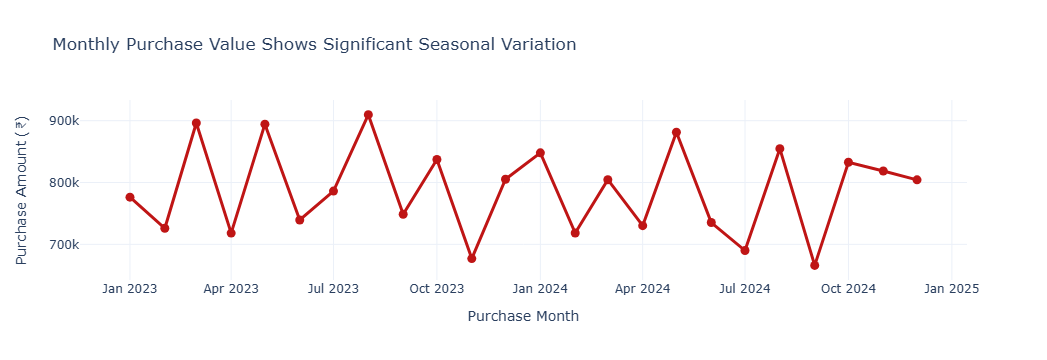

In [56]:
monthly_sales = customers_shopping.groupby(
    ["Year", "Month"],
    as_index=False,
).agg(
    sales=("Purchase Amount (₹)", "sum"),
)

monthly_sales["Date"] = pd.to_datetime(
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str)
    + "-01"
)

monthly_sales = monthly_sales.sort_values(
    by="Date"
)

fig_monthly_sales = px.line(
    monthly_sales,
    x="Date",
    y="sales",
    markers=True,
    hover_name="Year",
    labels={
        "Date":"Purchase Month",
        "sales":"Purchase Amount (₹)",
    },
    template = "plotly_white",
    title="Monthly Purchase Value Shows Significant Seasonal Variation",
)
fig_monthly_sales.update_traces(
    line=dict(color="#BF1515", width=3),
    marker=dict(size=9, color="#BF1515"),
)
fig_monthly_sales.show()

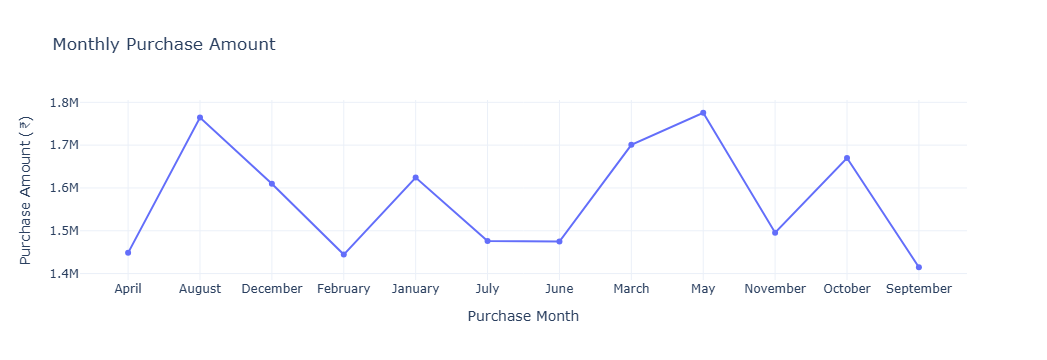

In [57]:
monthly_purchase = customers_shopping.groupby(
    ["Month_Name"],
    as_index=False,
).agg(
    purchase_amount=("Purchase Amount (₹)", "sum"),
)

fig_monthly_purchase = px.line(
    monthly_purchase,
    x="Month_Name",
    y="purchase_amount",
    hover_name="Month_Name",
    markers = True,
    hover_data={
        "Month_Name": False,
        "purchase_amount": ":,.2f",
    },
    labels={
        "Month_Name":"Purchase Month",
        "purchase_amount":"Purchase Amount (₹)",
    },
    title="Monthly Purchase Amount",
    template = "plotly_white"
)

fig_monthly_purchase.show()

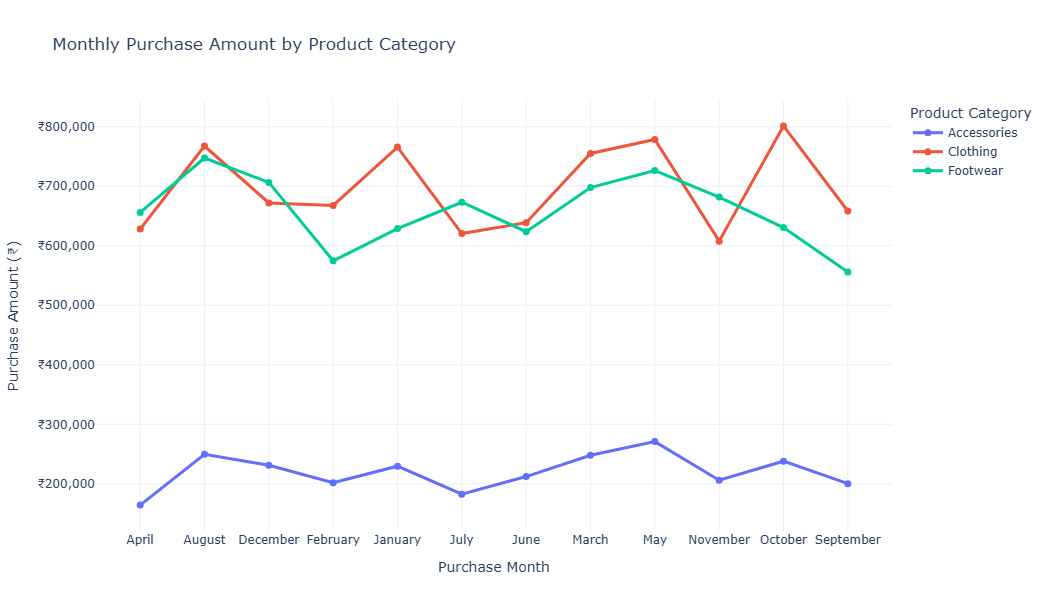

In [58]:
monthly_category_sales = customers_shopping.groupby(
    ["Month_Name", "Category"],
    as_index=False,
).agg(
    purchase_amount=("Purchase Amount (₹)", "sum"),
)

monthly_category_sales = monthly_category_sales.sort_values(
    by="Month_Name"
)

fig_monthly_category = px.line(
    monthly_category_sales,
    x="Month_Name",
    y="purchase_amount",
    color="Category",
    markers=True,
    hover_name="Category",
    hover_data={
        "Month_Name": True,
        "purchase_amount": ":,.0f",
        "Category": False,
    },
    labels={
        "Month_Name":"Purchase Month",
        "purchase_amount":"Purchase Amount (₹)",
        "Category":"Product Category",
    },
    title="Monthly Purchase Amount by Product Category",
)

fig_monthly_category.update_traces(
    line={
        "width":3,
    },
    marker={
        "size":7,
    },
)

fig_monthly_category.update_layout(
    template="plotly_white",
    width=1250,
    height=550,
    hovermode="x unified",
    legend_title_text="Product Category",
    xaxis={
        "title":"Purchase Month",
        "showgrid":True,
    },
    yaxis={
        "title":"Purchase Amount (₹)",
        "tickprefix":"₹",
        "tickformat":",.0f",
        "showgrid":True,
    },
)

fig_monthly_category.show()

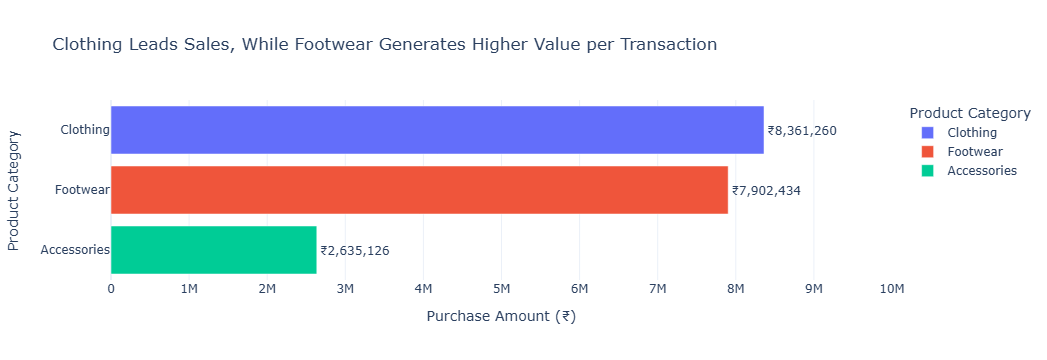

In [59]:
category_sales = customers_shopping.groupby(
    ["Category"],
    as_index=False,
).agg(
    sales=("Purchase Amount (₹)", "sum"),
    transactions=("Transaction ID", "nunique"),
)

category_sales = category_sales.sort_values(
    by="sales",
    ascending=False,
)

fig_category_sales = px.bar(
    category_sales,
    x="sales",
    y="Category",
    color="Category",
    text="sales",
    hover_name = "Category",
    range_x = [0,10000000],
    labels={
        "sales":"Purchase Amount (₹)",
        "Category":"Product Category",
    },
    title="Clothing Leads Sales, While Footwear Generates Higher Value per Transaction",
    template = "plotly_white",
)

fig_category_sales.update_traces(
    texttemplate="₹%{text:,.0f}",
    textposition="outside",
)

fig_category_sales.show()

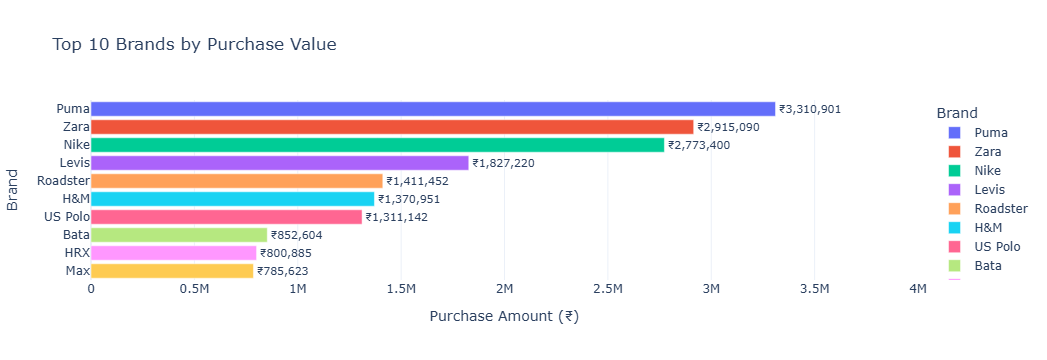

In [60]:
brand_sales = customers_shopping.groupby(
    ["Brand"],
    as_index=False,
).agg(
    sales=("Purchase Amount (₹)", "sum"),
)

brand_sales = brand_sales.sort_values(
    by="sales",
    ascending=False,
).head(10)

fig_brand_sales = px.bar(
    brand_sales,
    x="sales",
    y="Brand",
    color="Brand",
    text="sales",
    orientation="h",
    range_x=[0,4000000],
    hover_name = "Brand",
    labels={
        "sales":"Purchase Amount (₹)",
        "Brand":"Brand",
    },
    title="Top 10 Brands by Purchase Value",
    template = "plotly_white"
    
)

fig_brand_sales.update_traces(
    texttemplate="₹%{text:,.0f}",
    textposition="outside",
)

fig_brand_sales.show()

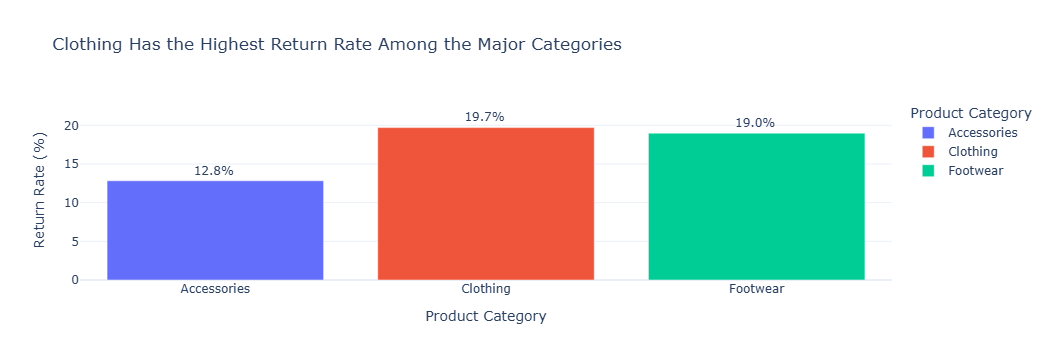

In [61]:
total_category = customers_shopping.groupby("Category").size()

returned_category = customers_shopping[customers_shopping["Return Status"] == "Returned"].groupby("Category").size()

category_returns = (returned_category / total_category) * 100

category_returns = category_returns.reset_index()

category_returns.columns = ["Category", "Returned"]

fig_category_returns = px.bar(
    category_returns,
    x="Category",
    y="Returned",
    color="Category",
    text="Returned",
    hover_name="Category",
    labels={
        "Returned": "Return Rate (%)",
        "Category": "Product Category",
    },
    title="Clothing Has the Highest Return Rate Among the Major Categories",
    template = "plotly_white"
)

fig_category_returns.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    
)

fig_category_returns.show()


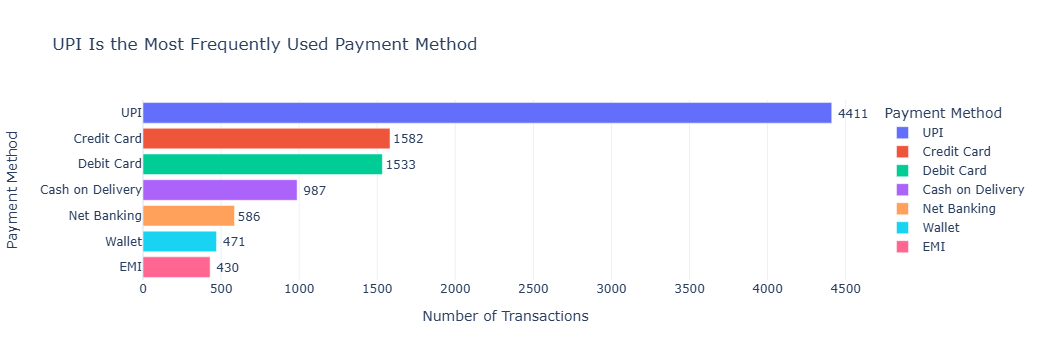

In [72]:
payment_sales = customers_shopping.groupby(
    ["Payment Method"],
    as_index=False,
).agg(
    transactions=("Transaction ID", "nunique"),
    sales=("Purchase Amount (₹)", "sum"),
)

payment_sales = payment_sales.sort_values(
    by="transactions",
    ascending=False,
)

bar_payment = px.bar(
    payment_sales,
    x="transactions",
    y="Payment Method",
    color="Payment Method",
    text="transactions",
    orientation="h",
    hover_name="Payment Method",
    labels={
        "transactions":"Number of Transactions",
        "Payment Method":"Payment Method",
    },
    title="UPI Is the Most Frequently Used Payment Method",
    template = "plotly_white"

)

bar_payment.update_traces(
    textposition="outside",
)

bar_payment.show()

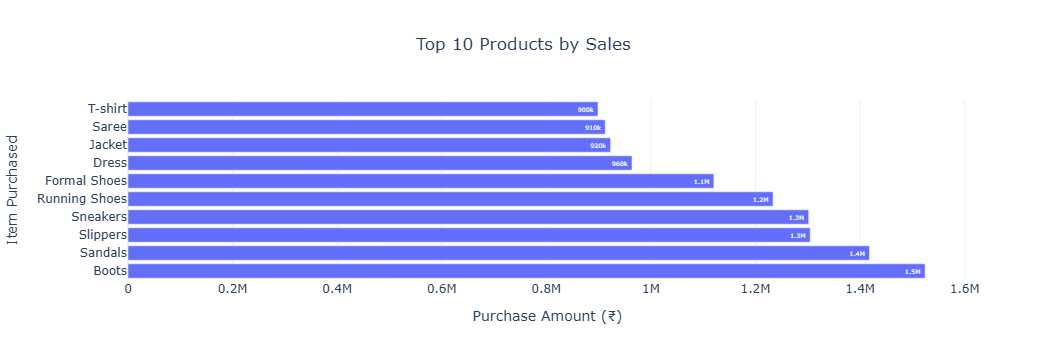

In [66]:
top_products = (
    customers_shopping.groupby("Item Purchased")["Purchase Amount (₹)"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products_bar = px.bar(
    top_products,
    x="Purchase Amount (₹)",
    y="Item Purchased",
    orientation="h",
    text_auto=".2s",
    title="Top 10 Products by Sales"
)

top_products_bar.update_layout(
    template="plotly_white",
    title_x=0.5
)

top_products_bar.show()

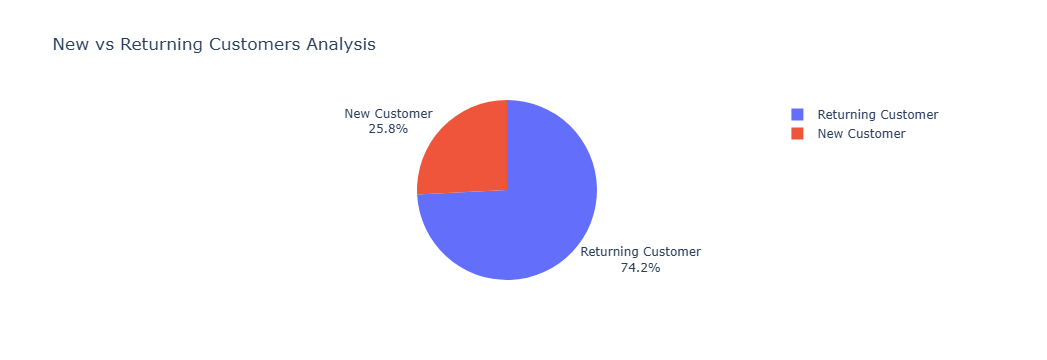

In [64]:
channel_sales = (
    customers_shopping["Customer Type"]
    .value_counts()
    .rename_axis("Customer Types")
    .reset_index(name = "Number Of Customers")
    
)
pie_channel = px.pie(
    channel_sales,
    names="Customer Types",
    values="Number Of Customers",
    title="New vs Returning Customers Analysis",
    hover_name = "Customer Types",
    template = "plotly_white"

)

pie_channel.update_traces(
    textinfo="percent+label",
    textposition = "outside"
)

pie_channel.show()

In [74]:
channel_sales = customers_shopping.groupby(
    ["Online/Offline"],
    as_index=False,
).agg(
    sales=("Purchase Amount (₹)", "sum"),
)
print(channel_sales)

  Online/Offline     sales
0        Offline   4386093
1         Online  14512727


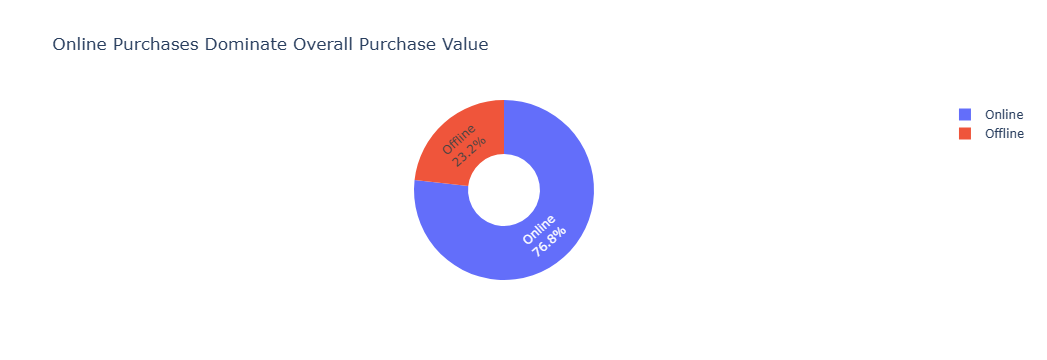

In [75]:
purchases_dominate_pie = px.pie(
    channel_sales,
    names="Online/Offline",
    values="sales",
    hole=0.4,
    title="Online Purchases Dominate Overall Purchase Value",
    hover_name = "Online/Offline",
    template = "plotly_white"

)

purchases_dominate_pie.update_traces(
    textinfo="percent+label",
)

purchases_dominate_pie.show()

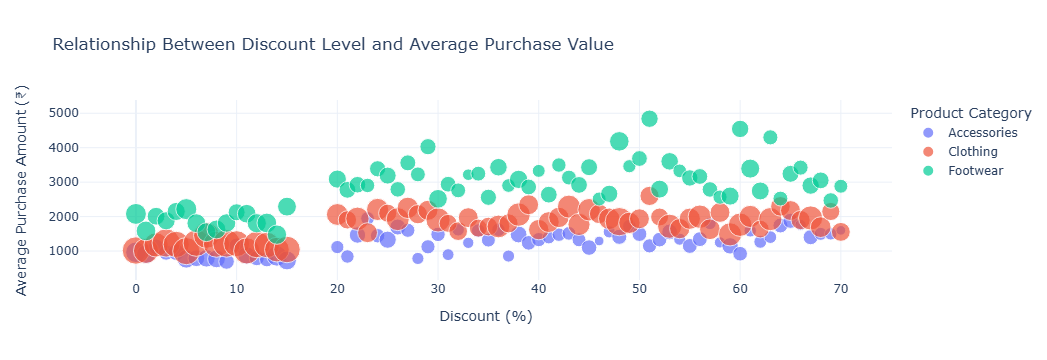

In [67]:
discount_analysis = customers_shopping.groupby(
    ["Discount (%)", "Category"],
    as_index=False,
).agg(
    average_purchase=("Purchase Amount (₹)", "mean"),
    transactions=("Transaction ID", "nunique"),
)

discount_analysis = discount_analysis.sort_values(
    by="Discount (%)"
)

fig_discount = px.scatter(
    discount_analysis,
    x="Discount (%)",
    y="average_purchase",
    color="Category",
    size="transactions",
    hover_name="Category",
    hover_data=[
        "transactions",
    ],
    labels={
        "Discount (%)":"Discount (%)",
        "average_purchase":"Average Purchase Amount (₹)",
        "Category":"Product Category",
        "transactions":"Transactions",
    },
    title="Relationship Between Discount Level and Average Purchase Value",
    template = "plotly_white"
)

fig_discount.show()

In [68]:
category_purchase = customers_shopping.groupby(
    ["Category"],
    as_index=False,
).agg(
    average_purchase=("Purchase Amount (₹)", "mean"),
    transactions=("Transaction ID", "nunique"),
)
category_purchase

,Category,average_purchase,transactions
0,Accessories,1220.530801,2159
1,Clothing,1671.249250,5003
2,Footwear,2784.508104,2838


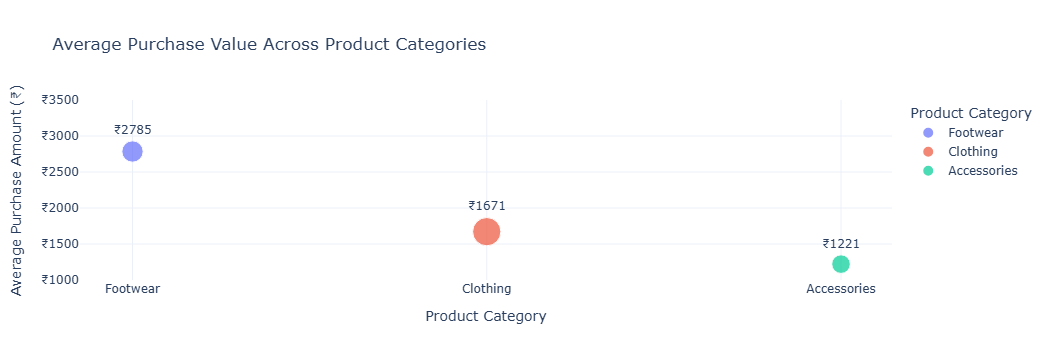

In [86]:
category_purchase = category_purchase.sort_values(
    by="average_purchase",
    ascending=False,
)

category_purchase_scatter = px.scatter(
    category_purchase,
    x="Category",
    y="average_purchase",
    range_y = [1000,3500],
    size="transactions",
    color="Category",
    text="average_purchase",
    hover_data=[
        "transactions",
    ],
    labels={
        "Category":"Product Category",
        "average_purchase":"Average Purchase Amount (₹)",
        "transactions":"Number of Transactions",
    },
    title="Average Purchase Value Across Product Categories",
    template = "plotly_white"
)

category_purchase_scatter.update_traces(
    texttemplate="₹%{text:.0f}",
    textposition="top center",
)

category_purchase_scatter.update_layout(
    yaxis_tickprefix="₹",
)

category_purchase_scatter.show()

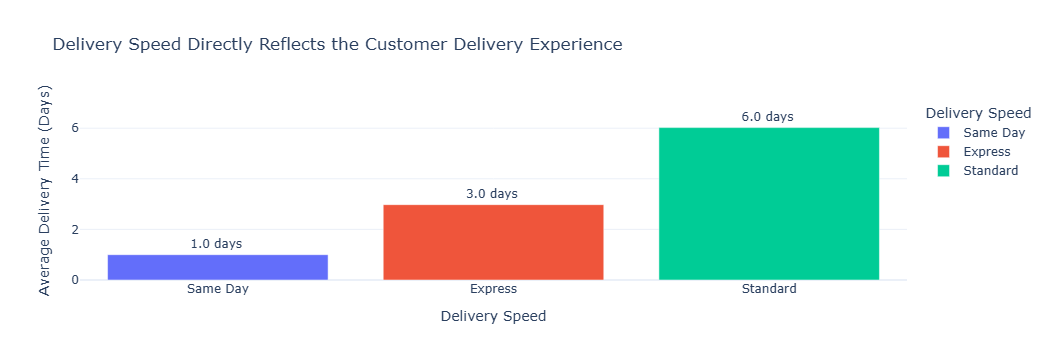

In [70]:
###
delivery_analysis = online_customers_shopping.groupby(          
    ["Delivery Speed"],
    as_index=False,
).agg(
    average_delivery_time=(
        "Delivery Time (Days)",
        "mean"
    ),
)

delivery_analysis = delivery_analysis.sort_values(
    by="average_delivery_time"
)

bar_delivery = px.bar(
    delivery_analysis,
    x="Delivery Speed",
    y="average_delivery_time",
    color="Delivery Speed",
    text="average_delivery_time",
    hover_name="Delivery Speed",
    labels={
        "Delivery Speed":"Delivery Speed",
        "average_delivery_time":"Average Delivery Time (Days)",
    },
    title="Delivery Speed Directly Reflects the Customer Delivery Experience",
    template = "plotly_white"
)

bar_delivery.update_traces(
    texttemplate="%{text:.1f} days",
    textposition="outside",
)

bar_delivery.show()

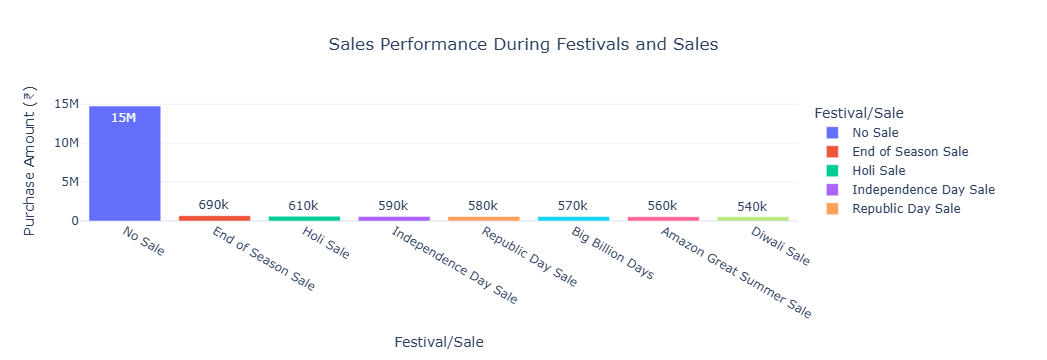

In [87]:
festival_sales = (
    customers_shopping.groupby("Festival/Sale")["Purchase Amount (₹)"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

festival_sales_bar = px.bar(
    festival_sales,
    x="Festival/Sale",
    y="Purchase Amount (₹)",
    color="Festival/Sale",
    text_auto=".2s",
    title="Sales Performance During Festivals and Sales"
)

festival_sales_bar.update_layout(
    template="plotly_white",
    title_x=0.5
)

festival_sales_bar.show()

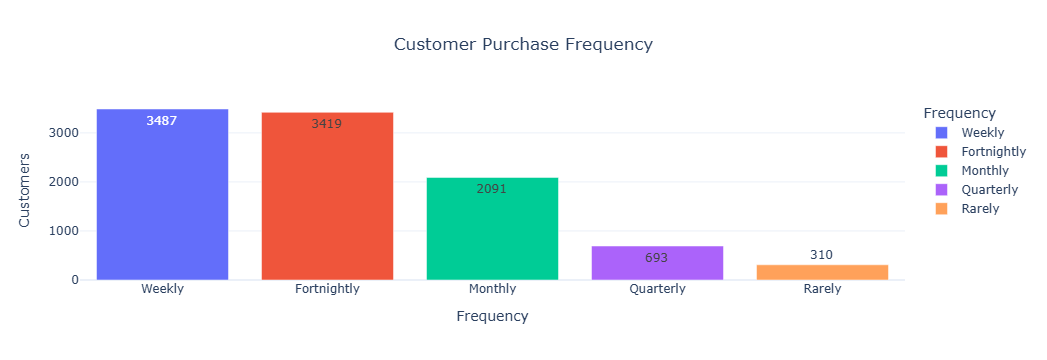

In [77]:
frequency = (
    customers_shopping["Frequency of Purchases"]
    .value_counts()
    .reset_index()
)

frequency.columns = ["Frequency", "Customers"]

frequency_bar = px.bar(
    frequency,
    x="Frequency",
    y="Customers",
    color="Frequency",
    text="Customers",
    title="Customer Purchase Frequency"
)

frequency_bar.update_layout(
    template="plotly_white",
    title_x=0.5
)

frequency_bar.show()

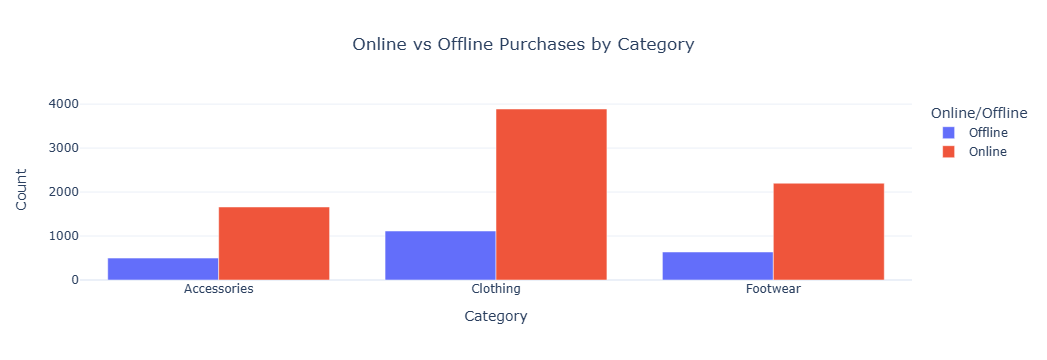

In [78]:
channel_category = (
    customers_shopping.groupby(
        ["Category", "Online/Offline"]
    ).size()
    .reset_index(name="Count")
)

channel_category_stackedbar = px.bar(
    channel_category,
    x="Category",
    y="Count",
    color="Online/Offline",
    barmode="group",
    title="Online vs Offline Purchases by Category"
)

channel_category_stackedbar.update_layout(
    template="plotly_white",
    title_x=0.5
)

channel_category_stackedbar.show()

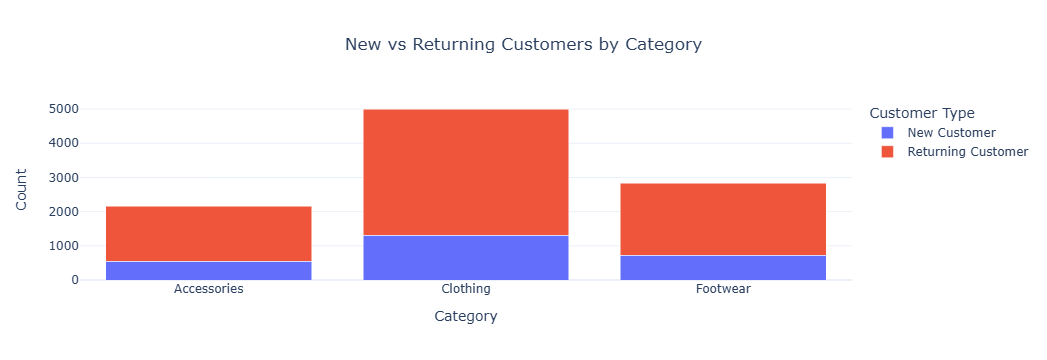

In [79]:
category_customer = (
    customers_shopping.groupby(
        ["Category", "Customer Type"]
    ).size()
    .reset_index(name="Count")
)

category_customer_stackedbar = px.bar(
    category_customer,
    x="Category",
    y="Count",
    color="Customer Type",
    barmode="stack",
    title="New vs Returning Customers by Category"
)

category_customer_stackedbar.update_layout(
    template="plotly_white",
    title_x=0.5
)

category_customer_stackedbar.show()

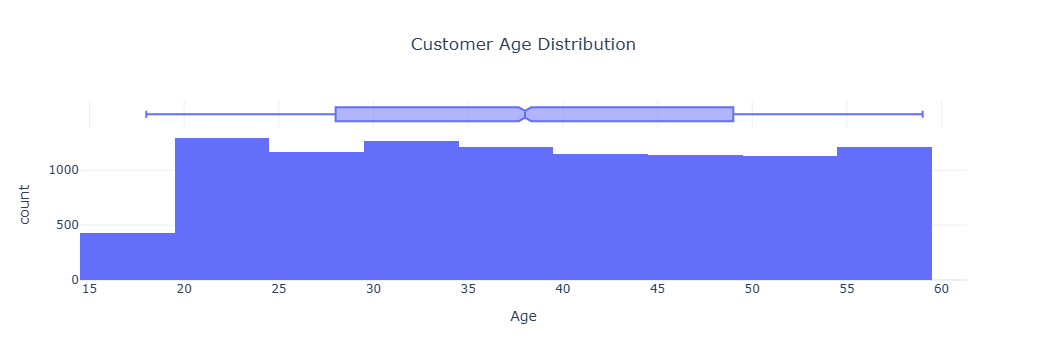

In [80]:
age_histogram = px.histogram(
    customers_shopping,
    x="Age",
    nbins=20,
    title="Customer Age Distribution",
    marginal="box"
)

age_histogram.update_layout(
    template="plotly_white",
    title_x=0.5
)

age_histogram.show()

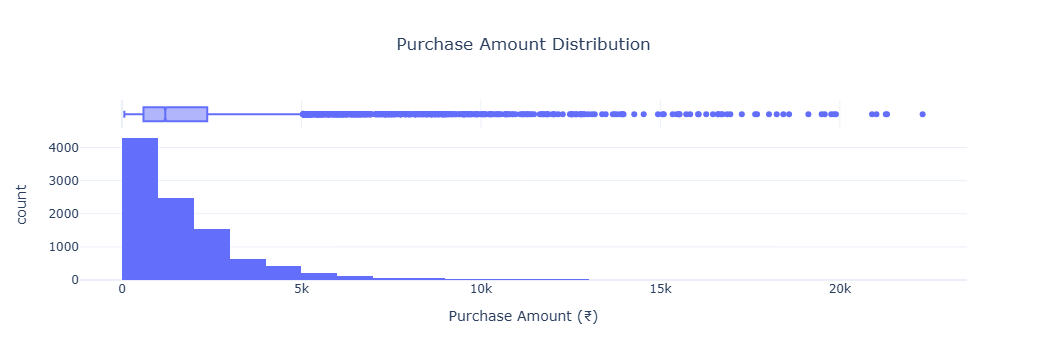

In [81]:
purchase_ammount_histogram = px.histogram(
    customers_shopping,
    x="Purchase Amount (₹)",
    nbins=30,
    title="Purchase Amount Distribution",
    marginal="box"
    
)

purchase_ammount_histogram.update_layout(
    template="plotly_white",
    title_x=0.5
)

purchase_ammount_histogram.show()

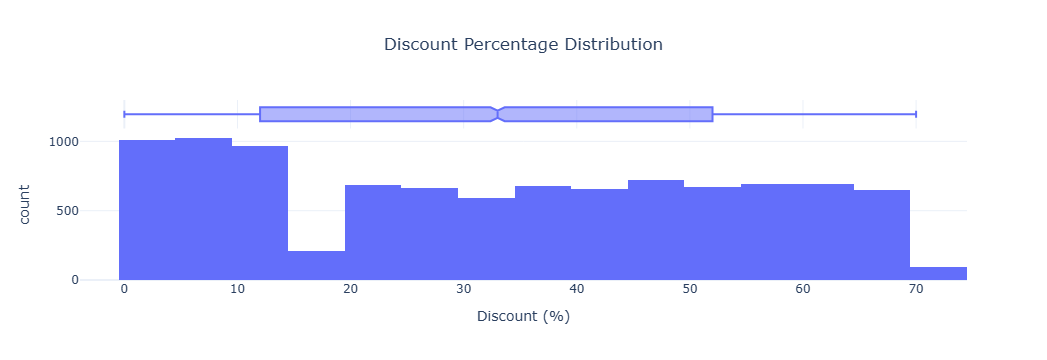

In [82]:
discount_percentage_histogram = px.histogram(
    customers_shopping,
    x="Discount (%)",
    nbins=20,
    title="Discount Percentage Distribution",
    marginal="box"
)

discount_percentage_histogram.update_layout(
    template="plotly_white",
    title_x=0.5
)

discount_percentage_histogram.show()

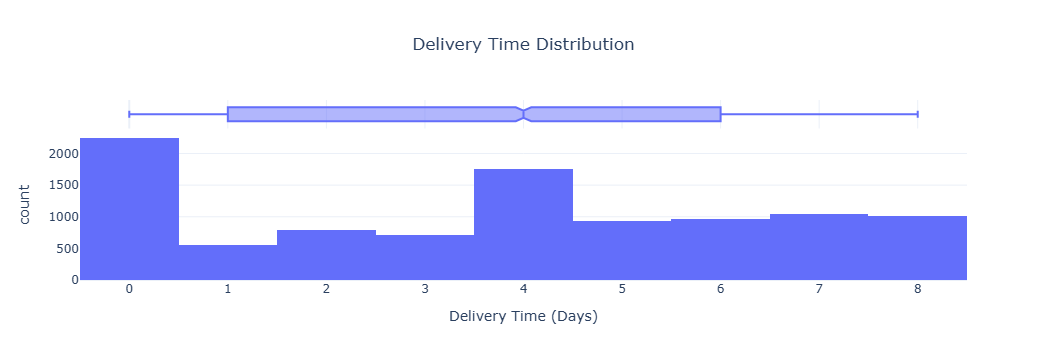

In [83]:
delivery_time_histogram = px.histogram(
    customers_shopping,
    x="Delivery Time (Days)",
    nbins=10,
    title="Delivery Time Distribution",
    marginal="box"
)

delivery_time_histogram.update_layout(
    template="plotly_white",
    title_x=0.5
)

delivery_time_histogram.show()

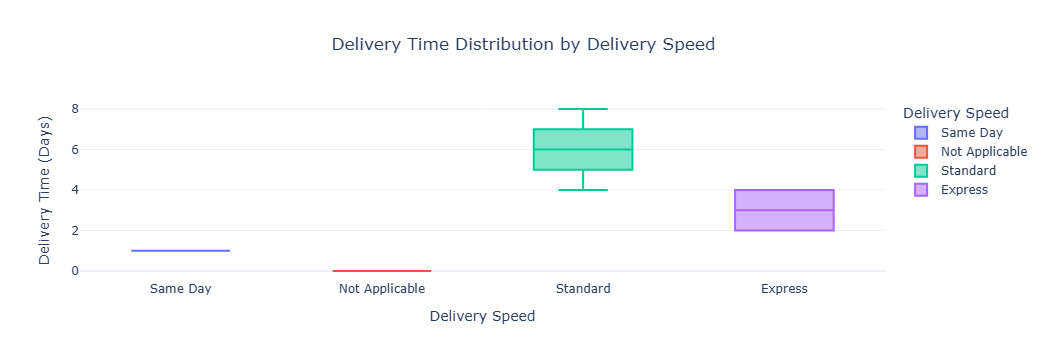

In [84]:
delivery_time_box= px.box(
    customers_shopping,
    x="Delivery Speed",
    y="Delivery Time (Days)",
    color="Delivery Speed",
    title="Delivery Time Distribution by Delivery Speed"
)

delivery_time_box.update_layout(
    template="plotly_white",
    title_x=0.5
)

delivery_time_box.show()

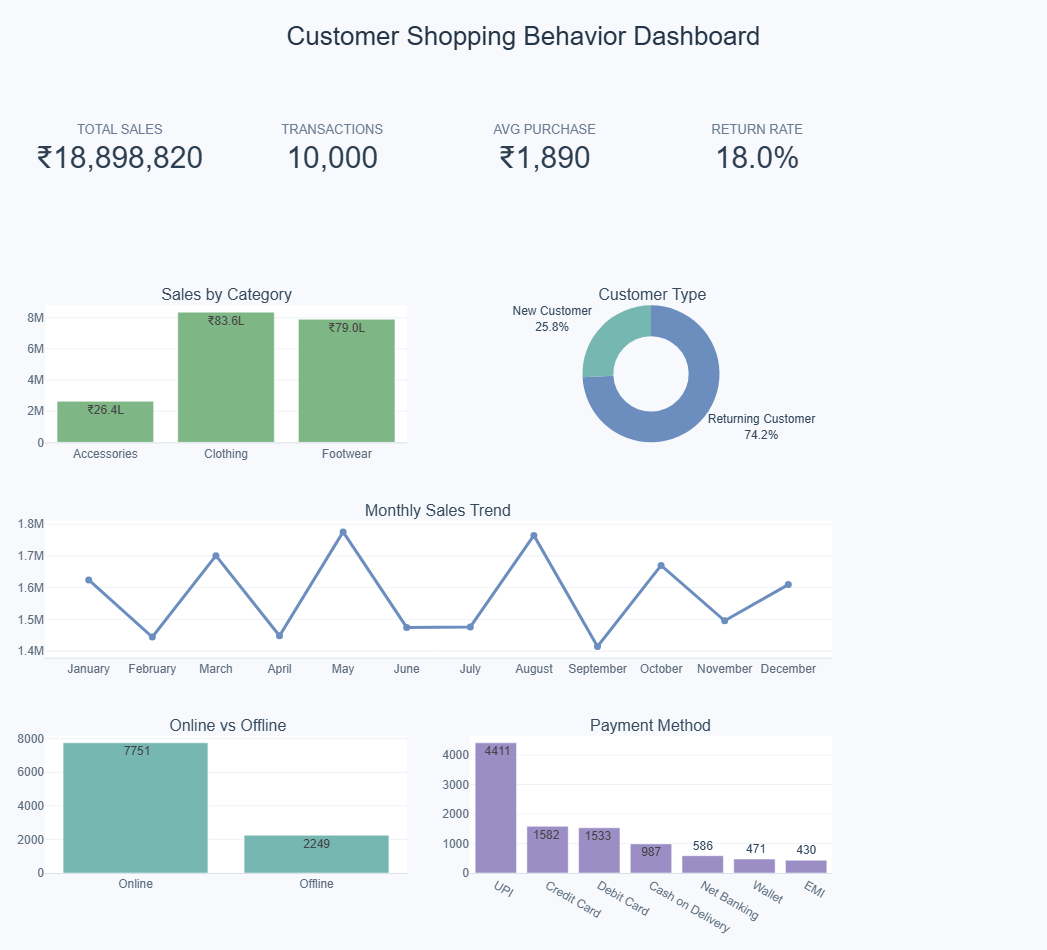

In [85]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

customers_shopping["Month_Name"] = pd.Categorical(
    customers_shopping["Month_Name"],
    categories=month_order,
    ordered=True
)


total_sales = customers_shopping[
    "Purchase Amount (₹)"
].sum()

total_transactions = len(customers_shopping)

average_purchase = customers_shopping[
    "Purchase Amount (₹)"
].mean()

return_rate = (
    (customers_shopping["Return Status"] == "Returned").mean()
    * 100
)


category_sales = (
    customers_shopping
    .groupby("Category")["Purchase Amount (₹)"]
    .sum()
    .reset_index()
)



customer_type = (
    customers_shopping["Customer Type"]
    .value_counts()
    .reset_index()
)

customer_type.columns = [
    "Customer Type",
    "Count"
]


monthly_sales = (
    customers_shopping
    .groupby(
        "Month_Name",
        observed=True
    )["Purchase Amount (₹)"]
    .sum()
    .reset_index()
)


channel = (
    customers_shopping["Online/Offline"]
    .value_counts()
    .reset_index()
)

channel.columns = [
    "Online/Offline",
    "Count"
]


payment = (
    customers_shopping["Payment Method"]
    .value_counts()
    .reset_index()
)

payment.columns = [
    "Payment Method",
    "Count"
]


dashboard = make_subplots(

    rows=4,
    cols=4,

    specs=[

        # KPI row
        [
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"}
        ],

        # Category + Customer type
        [
            {"type": "bar", "colspan": 2},
            None,
            {"type": "domain", "colspan": 2},
            None
        ],

        # Monthly trend
        [
            {"type": "xy", "colspan": 4},
            None,
            None,
            None
        ],

        # Bottom charts
        [
            {"type": "bar", "colspan": 2},
            None,
            {"type": "bar", "colspan": 2},
            None
        ]
    ],

    vertical_spacing=0.10,

    horizontal_spacing=0.08,

    subplot_titles=[
        "",
        "",
        "",
        "",
        "Sales by Category",
        "Customer Type",
        "Monthly Sales Trend",
        "Online vs Offline",
        "Payment Method"
    ]
)


dashboard.add_trace(

    go.Indicator(
        mode="number",

        value=total_sales,

        title={
            "text": "TOTAL SALES"
        },

        number={
            "prefix": "₹",
            "valueformat": ",.0f"
        }
    ),

    row=1,
    col=1
)


dashboard.add_trace(

    go.Indicator(
        mode="number",

        value=total_transactions,

        title={
            "text": "TRANSACTIONS"
        },

        number={
            "valueformat": ",.0f"
        }
    ),

    row=1,
    col=2
)


dashboard.add_trace(

    go.Indicator(
        mode="number",

        value=average_purchase,

        title={
            "text": "AVG PURCHASE"
        },

        number={
            "prefix": "₹",
            "valueformat": ",.0f"
        }
    ),

    row=1,
    col=3
)


dashboard.add_trace(

    go.Indicator(
        mode="number",

        value=return_rate,

        title={
            "text": "RETURN RATE"
        },

        number={
            "suffix": "%",
            "valueformat": ".1f"
        }
    ),

    row=1,
    col=4
)


dashboard.add_trace(

    go.Bar(

        x=category_sales["Category"],

        y=category_sales[
            "Purchase Amount (₹)"
        ],

        text=[
            f"₹{x/100000:.1f}L"
            for x in category_sales[
                "Purchase Amount (₹)"
            ]
        ],

        textposition="auto",

        name="Sales"

    ),

    row=2,
    col=1
)


dashboard.add_trace(

    go.Pie(

        labels=customer_type[
            "Customer Type"
        ],

        values=customer_type[
            "Count"
        ],

        hole=0.55,

        textinfo="percent+label",

        name="Customer Type"

    ),

    row=2,
    col=3
)


dashboard.add_trace(

    go.Scatter(

        x=monthly_sales[
            "Month_Name"
        ],

        y=monthly_sales[
            "Purchase Amount (₹)"
        ],

        mode="lines+markers",

        name="Monthly Sales"

    ),

    row=3,
    col=1
)


dashboard.add_trace(

    go.Bar(

        x=channel[
            "Online/Offline"
        ],

        y=channel[
            "Count"
        ],

        text=channel[
            "Count"
        ],

        textposition="auto",

        name="Channel"

    ),

    row=4,
    col=1
)


dashboard.add_trace(

    go.Bar(

        x=payment[
            "Payment Method"
        ],

        y=payment[
            "Count"
        ],

        text=payment[
            "Count"
        ],

        textposition="auto",

        name="Payment"

    ),

    row=4,
    col=3
)


dashboard.update_layout(

    title={
        "text": "Customer Shopping Behavior Dashboard",

        "x": 0.5,

        "xanchor": "center",

        "font": {
            "size": 26,
            "color": "#243447"
        }
    },

    paper_bgcolor="#F7F9FC",

    plot_bgcolor="#FFFFFF",

    template="plotly_white",

    height=950,

    showlegend=False,

    margin={
        "l": 45,
        "r": 45,
        "t": 90,
        "b": 45
    },

    font={
        "family": "Arial",
        "color": "#34495E"
    }
)


dashboard.update_xaxes(

    showgrid=False,

    linecolor="#D9E1EA",

    tickfont={
        "color": "#5D6D7E"
    }
)


dashboard.update_yaxes(

    showgrid=True,

    gridcolor="#EEF2F6",

    zeroline=False,

    tickfont={
        "color": "#5D6D7E"
    }
)


light_colors = [

    "#6C8EBF",   # Soft blue
    "#76B7B2",   # Soft teal
    "#9B8EC4",   # Soft lavender
    "#E8A87C",   # Soft peach
    "#7FB685",   # Soft green
    "#D88C9A"    # Soft pink

]


for i, trace in enumerate(dashboard.data):

    if trace.type == "bar":

        trace.marker.color = (
            light_colors[
                i % len(light_colors)
            ]
        )

    elif trace.type == "pie":

        trace.marker.colors = (
            light_colors
        )

    elif trace.type == "scatter":

        trace.line.color = "#6C8EBF"

        trace.marker.color = "#6C8EBF"

        trace.line.width = 3

        trace.marker.size = 7


for trace in dashboard.data:

    if trace.type == "indicator":

        trace.number.font = {
            "size": 30,
            "color": "#2C3E50"
        }

        trace.title.font = {
            "size": 13,
            "color": "#6B7C93"
        }


dashboard.show()

